In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("sample_data/credit_risk_dataset.csv")

In [3]:
#EDA- looking at data and understanding it without touching it
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [4]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [5]:
df['loan_status'].unique()
#we have a classification problem

array([1, 0])

In [6]:
df['loan_status'].value_counts()  #class imbalance

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

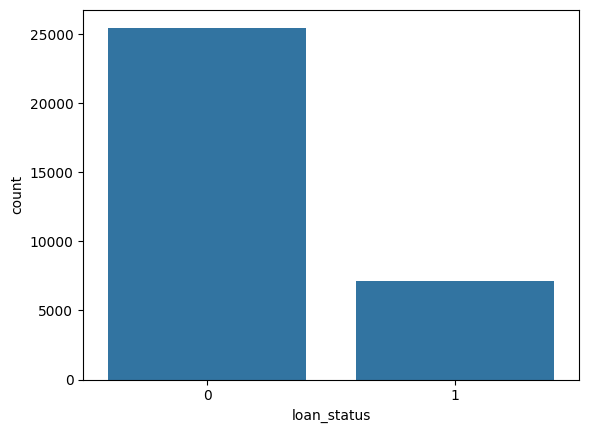

In [7]:
sns.countplot(df,x='loan_status')

In [8]:
#checking outliers n correlation
df['person_age'].describe()

,person_age
count,32581.000000
mean,27.734600
std,6.348078
min,20.000000
25%,23.000000
50%,26.000000
75%,30.000000
max,144.000000


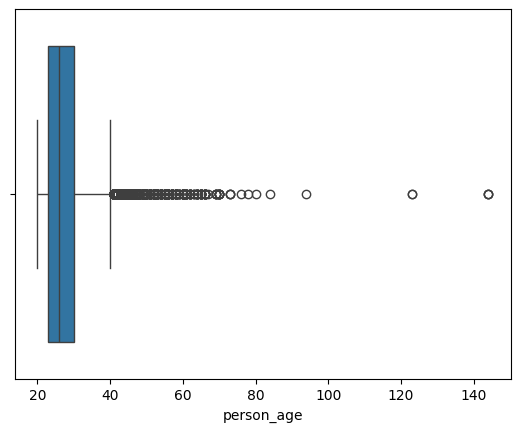

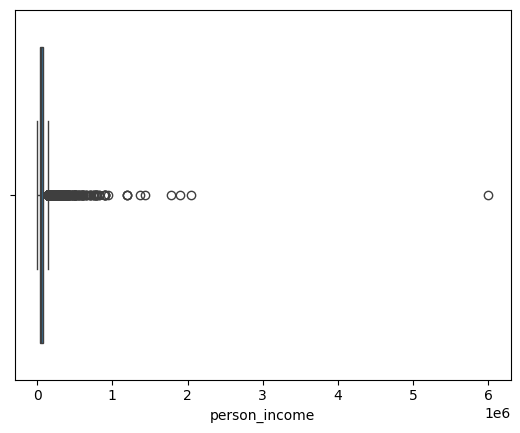

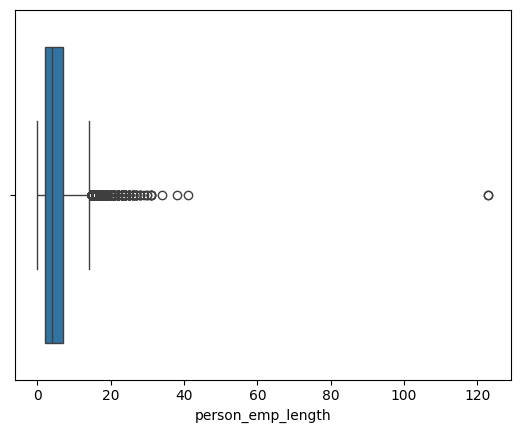

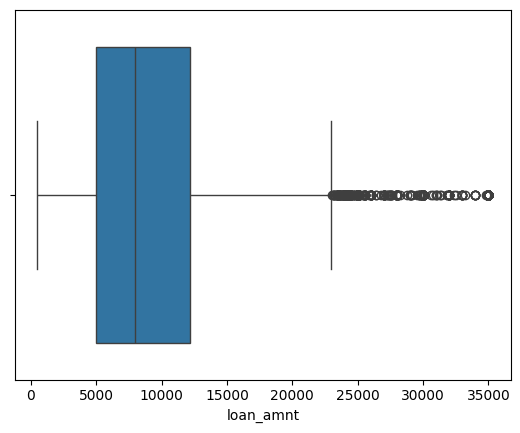

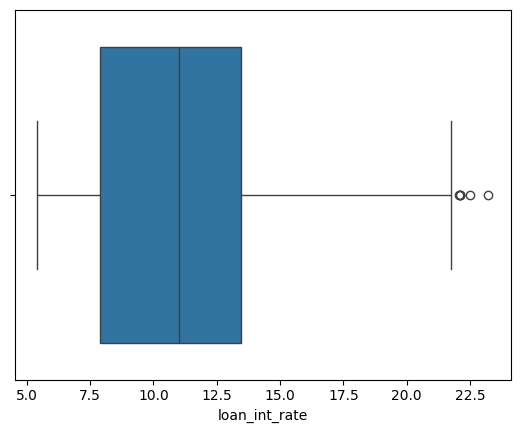

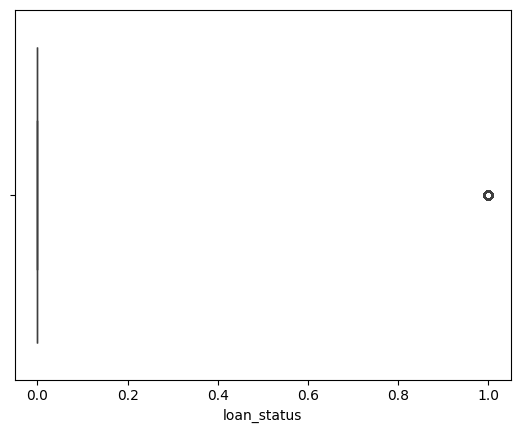

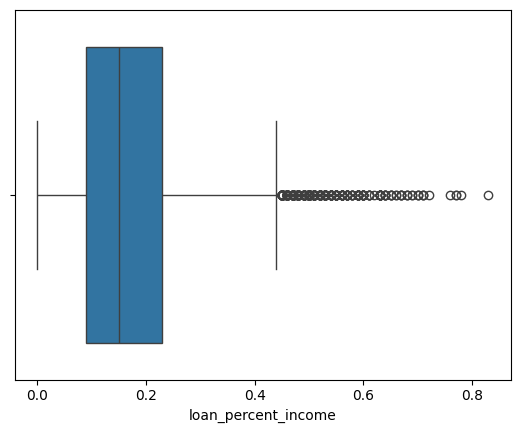

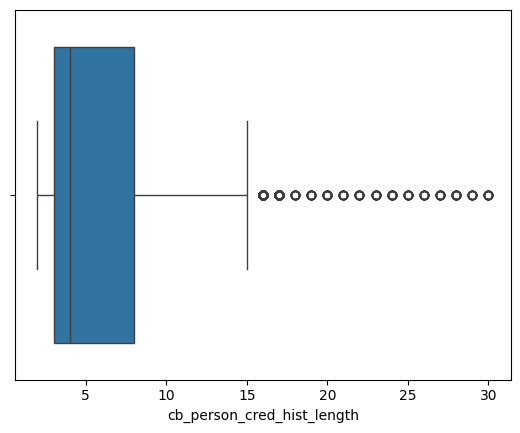

In [9]:
numerical_cols=df.select_dtypes(include='number').columns
for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()

In [10]:
df[df['person_emp_length'] > 60]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4


In [11]:
df[df['person_age'] > 100]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
81,144,250000,RENT,4.0,VENTURE,C,4800,13.57,0,0.02,N,3
183,144,200000,MORTGAGE,4.0,EDUCATION,B,6000,11.86,0,0.03,N,2
575,123,80004,RENT,2.0,EDUCATION,B,20400,10.25,0,0.25,N,3
747,123,78000,RENT,7.0,VENTURE,B,20000,NaN,0,0.26,N,4
32297,144,6000000,MORTGAGE,12.0,PERSONAL,C,5000,12.73,0,0.00,N,25


<Axes: >

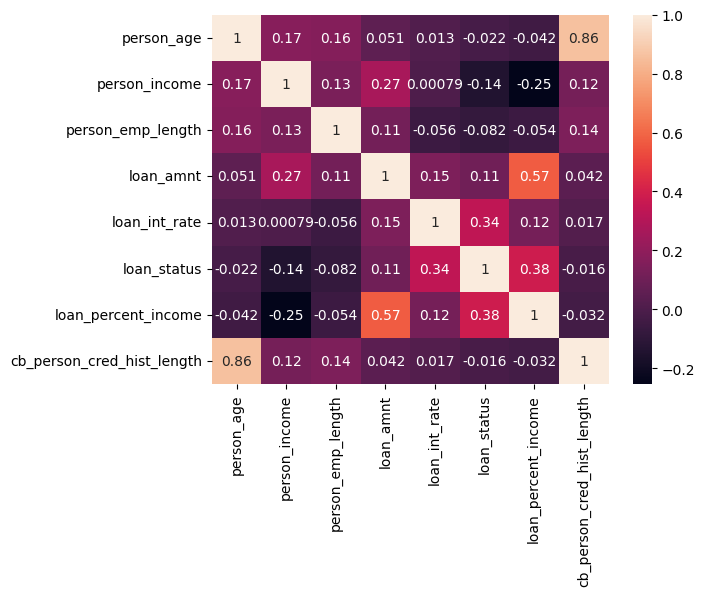

In [12]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [13]:
#handling outliers is very very imp-otherwise model drifts

In [14]:
df.duplicated().sum()

np.int64(165)

In [15]:
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [16]:
df['loan_intent'].value_counts()

,count
loan_intent,
EDUCATION,6453
MEDICAL,6071
VENTURE,5719
PERSONAL,5521
DEBTCONSOLIDATION,5212
HOMEIMPROVEMENT,3605


In [17]:
df['loan_grade'].value_counts()

,count
loan_grade,
A,10777
B,10451
C,6458
D,3626
E,964
F,241
G,64


In [18]:
#now making actual changes to data after seeing problems
df_copy=df.copy()
df_copy.drop_duplicates(inplace=True)

In [19]:
df_copy=df_copy[(df_copy['person_age'] >= 18) | (df_copy['person_age'] <= 100)]

In [20]:
df_copy

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [21]:
df_copy=df_copy[df_copy['person_emp_length'] <= 60 ]

In [22]:
df_copy=df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]

In [23]:
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [24]:
df_copy[df_copy['loan_amnt'] <= 0]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


In [25]:
X=df_copy.drop('loan_status',axis=1)
y=df_copy['loan_status']

In [26]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
#stratify- distributes 1 and 0 class equally in train and test split

In [27]:
numerical_cols=['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']
categorical_cols=['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file']

In [28]:
#we handle class imbalance using smote and class weights
#w r using class weights- tells model to focus same on the class whose freq is less
#logistic reg has this ibuilt
#so we r using this as baseline model as xgboost that we r mainly going to use doesnt have class weights

In [29]:
y_train.value_counts()

,count
loan_status,
0,19776
1,5445


In [30]:
neg , pos =np.bincount(y_train)

In [31]:
neg

np.int64(19776)

In [32]:
pos

np.int64(5445)

In [33]:
scale_weights=neg/pos
scale_weights

np.float64(3.631955922865014)

In [34]:
scale_weights=neg/pos

In [35]:
scale_weights=neg/pos
#now xg boost will be given this

In [36]:
df_copy

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [37]:
#lOGISTIC reg- impute + scaling , impute + one hot encoding
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression

preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num',
         Pipeline([
             ('imputer', SimpleImputer(strategy='mean')),
             ('scaler', StandardScaler())
         ]),
         numerical_cols),
        ('cat',
         Pipeline([
             ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
             ('onehot', OneHotEncoder(handle_unknown='ignore'))
         ]),
         categorical_cols)
    ]
)

In [38]:

#XGBOOST pipeline  ... only impute
#scaling not required for xgboost
#, impute+onehot


preprocessor_xg= ColumnTransformer(
    transformers=[
        ('num',
         Pipeline([
             ('imputer', SimpleImputer(strategy='mean'))
         ]),
         numerical_cols),
        ('cat',
         Pipeline([
             ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
             ('onehot', OneHotEncoder(handle_unknown='ignore'))
         ]),
         categorical_cols)
    ]
)


In [39]:
from sklearn.model_selection import StratifiedKFold
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

scoring={'roc_auc':'roc_auc','accuracy':'accuracy','precision':'precision','recall':'recall'}

In [40]:
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline=Pipeline(
    [('preprocessor',preprocessor_lr),
     ('classifier',LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42))]
)
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [41]:
from xgboost import XGBClassifier
xgb_cv_pipeline=Pipeline(
    [('preprocessor',preprocessor_xg),
     ('classifier',XGBClassifier(n_estimator=300,max_depth=5,learning_rate=0.1,scale_pos_weight=scale_weights,random_state=42))]
)
xgb_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   O...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

In [42]:
from sklearn.model_selection import cross_validate
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:
    cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,n_jobs=-1)
    print(cv_name)
    print(f"{cv_name} cross validation scores:")
    print(f"ROC AUC: {cv_results['test_roc_auc'].mean()}")
    print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
    print(f"Precision: {cv_results['test_precision'].mean()}")
    print(f"Recall: {cv_results['test_recall'].mean()}")
    print(f"F1 Score: {(2 * cv_results['test_precision'].mean() * cv_results['test_recall'].mean()) / (cv_results['test_precision'].mean() + cv_results['test_recall'].mean())}")


Logistic Regression
Logistic Regression cross validation scores:
ROC AUC: 0.8710057705162019
Accuracy: 0.8131317822389926
Precision: 0.5474593851847425
Recall: 0.7768595041322314
F1 Score: 0.6422909616980637
XGBoost
XGBoost cross validation scores:
ROC AUC: 0.9392826394677775
Accuracy: 0.9084096894798519
Precision: 0.7893564236072199
Recall: 0.7860422405876951
F1 Score: 0.787695846056325


#Lets create a helper that calculates all evaluation metrics

In [43]:
from sklearn.metrics._plot.precision_recall_curve import precision_recall_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,confusion_matrix,classification_report
def evaluate_model(model_name,model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    # #mterics
    # accuracy = accuracy_score(y_test, y_pred) #overall model performance (kitne barr sahi ko sahi bola vice versa)
    # precision = precision_score(y_test, y_pred) #Out of the ones I picked how many were correct?
    # recall = recall_score(y_test, y_pred)#Out of everything that was there how much did I manage to find?
    # f1_score=f1_score(y_test,y_pred)
    # confusion_matrix=confusion_matrix(y_test,y_pred)
    # classification_report=classification_report(y_test,y_pred)
    # roc_auc = roc_auc_score(y_test, y_pred_proba) #Area under the ROC curve

    acc_val = accuracy_score(y_test, y_pred)
    prec_val = precision_score(y_test, y_pred)
    rec_val = recall_score(y_test, y_pred)
    f1_val = f1_score(y_test, y_pred)
    roc_auc_val = roc_auc_score(y_test, y_pred_proba)
    cm_val = confusion_matrix(y_test, y_pred)
    cr_val = classification_report(y_test, y_pred)


    print(f"{model_name} Metrics:")
    print(f"Accuracy: {acc_val}")
    print(f"Precision: {prec_val}")
    print(f"Recall: {rec_val}")

    precision,recall,threshold=precision_recall_curve(y_test,y_pred_proba)
    plt.plot(rec_val,prec_val)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision Recall Curve")
    plt.show()

    print(f"F1 Score: {f1_val}")
    print(f"ROC AUC: {roc_auc_val}")
    #plotting roc curve
    fpr,tpr,_=roc_auc_curve(y_test,y_pred_proba)
    plt.plot(fpr,tpr)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.show()

    sns.heatmap(cm_val,annot=True)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.show()
    print(f"Classification Report:\n{cr_val}")




In [44]:
#Bseline Model
baseline_model=Pipeline(
    [('preprocessor',preprocessor_lr),
     ('classifier',LogisticRegression(class_weight='balanced'))]
)
baseline_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Baseline Model Metrics:
Accuracy: 0.8149381541389153
Precision: 0.5500256541816316
Recall: 0.7870778267254038


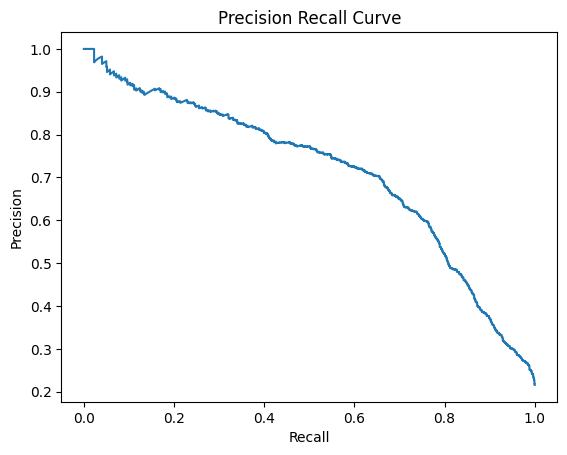

F1 Score: 0.6475385080036243
ROC AUC: 0.8732363409986266


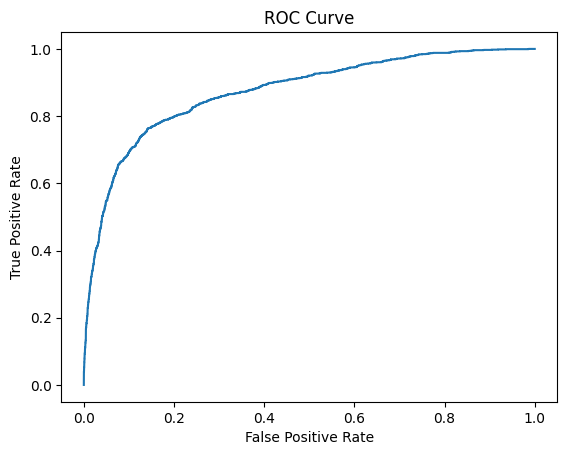

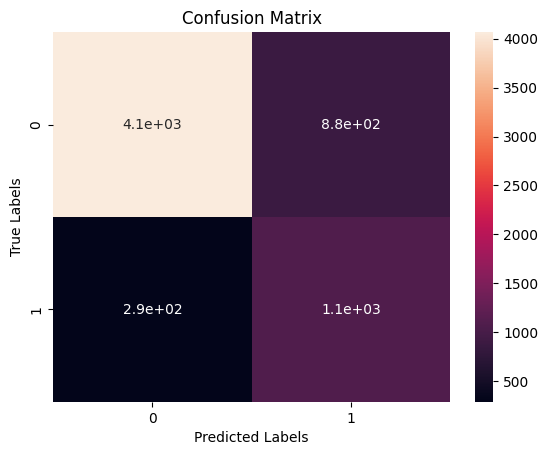

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      4944
           1       0.55      0.79      0.65      1362

    accuracy                           0.81      6306
   macro avg       0.74      0.80      0.76      6306
weighted avg       0.85      0.81      0.83      6306



In [57]:
from sklearn.metrics import roc_curve

# Redefining the function with the correct roc_curve function call
def evaluate_model(model_name, model, X_test, y_test,threshold=None):
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]


    if threshold is not None:
        y_pred = (y_pred_proba >= threshold).astype(int)
    else:
        y_pred = model.predict(X_test)
        y_pred_proba = model.predict_proba(X_test)[:, 1]
    # Calculate metrics

    acc_val = accuracy_score(y_test, y_pred)
    prec_val = precision_score(y_test, y_pred)
    rec_val = recall_score(y_test, y_pred)
    f1_val = f1_score(y_test, y_pred)
    roc_auc_val = roc_auc_score(y_test, y_pred_proba)
    cm_val = confusion_matrix(y_test, y_pred)
    cr_val = classification_report(y_test, y_pred)

    print(f"{model_name} Metrics:")
    print(f"Accuracy: {acc_val}")
    print(f"Precision: {prec_val}")
    print(f"Recall: {rec_val}")

    precision, recall, threshold = precision_recall_curve(y_test, y_pred_proba)
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision Recall Curve")
    plt.show()

    print(f"F1 Score: {f1_val}")
    print(f"ROC AUC: {roc_auc_val}")

    # Plotting ROC curve with the corrected function: roc_curve
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    plt.plot(fpr, tpr)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.show()

    sns.heatmap(cm_val, annot=True)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Labels")
    plt.ylabel("True Labels")
    plt.show()
    print(f"Classification Report:\n{cr_val}")

# Evaluating the Baseline Model
evaluate_model("Baseline Model", baseline_model, X_test, y_test)

In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve

# Correct evaluation logic directly
y_pred = baseline_model.predict(X_test)
y_pred_proba = baseline_model.predict_proba(X_test)[:, 1]

print("Baseline Model Metrics:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")

# Display classification report
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Baseline Model Metrics:
Accuracy: 0.8149
Precision: 0.5500
Recall: 0.7871
F1 Score: 0.6475
ROC AUC: 0.8732

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.82      0.87      4944
           1       0.55      0.79      0.65      1362

    accuracy                           0.81      6306
   macro avg       0.74      0.80      0.76      6306
weighted avg       0.85      0.81      0.83      6306



In [47]:
#hyperamter tuning on xg boost model
xg_model=Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(scale_pos_weight=scale_weights,random_state=42))
])

In [48]:
#hyperparameter tuning is done here using randomizedsearch cv
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform #due to stats , the below lists becomes iterable(distribution) whihc is needed

# Using scipy.stats distributions so RandomizedSearchCV can sample from them
param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": uniform(0.01, 0.49), # range [0.01, 0.01 + 0.49]
    "classifier__subsample": uniform(0.4, 0.2),       # range [0.4, 0.4 + 0.2]        sampling of rows (shuffling)
    "classifier__colsample_bytree": uniform(0.4, 0.2), # range [0.4, 0.4 + 0.2]   col sampling (shuffling)
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0, 10)               # controls splits
}

#lower gamma - more splits more tree depth - complex tree - higher overfitting risk
#higher gamma - less splits - simple tree - low overfitting risk

In [49]:
random_search=RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=50,
    cv=cv,
    scoring=scoring,
    refit='roc_auc', # Specifies which metric to use to find the best model configuration
    n_jobs=-1,
    verbose=1,
    random_state=42
)

random_search.fit(X_train,y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length']),
                                                                              ('cat',
                                                                               Pipeli...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d72c6369e50>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d72d0377620>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7d72c6369a90>},
                   random_state=42, refit='roc_auc',
                   scoring={'accuracy': 'accuracy', 'precision': 'precision',
                            'recall': 'recall', 'roc_auc': 'roc_auc'},
                   verbose=1)

In [50]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# 1. Pipelines
rf_model = Pipeline([
    ('preprocessor', preprocessor_lr), # Random Forest can use the scaled features preprocessor
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
])

ada_model = Pipeline([
    ('preprocessor', preprocessor_lr), # AdaBoost can use scaled features preprocessor
    ('classifier', AdaBoostClassifier(random_state=42))
])

# 2. Parameter Grids
rf_param_grid = {
    "classifier__n_estimators": randint(100, 500),
    "classifier__max_depth": randint(3, 12),
    "classifier__min_samples_split": randint(2, 11),
    "classifier__min_samples_leaf": randint(1, 10)
}

ada_param_grid = {
    "classifier__n_estimators": randint(50, 300),
    "classifier__learning_rate": uniform(0.01, 1.0)
}

# 3. Randomized Search Setup
rf_random_search = RandomizedSearchCV(
    rf_model,
    rf_param_grid,
    n_iter=50, # Lower iter to run reasonably fast
    cv=cv,
    scoring=scoring,
    refit='roc_auc',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

ada_random_search = RandomizedSearchCV(
    ada_model,
    ada_param_grid,
    n_iter=50,
    cv=cv,
    scoring=scoring,
    refit='roc_auc',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

Fitting Random Forest...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Random Forest search complete.
Evaluating Best Random Forest Model:
Tuned Random Forest Metrics:
Accuracy: 0.9203932762448461
Precision: 0.8675213675213675
Recall: 0.7452276064610867


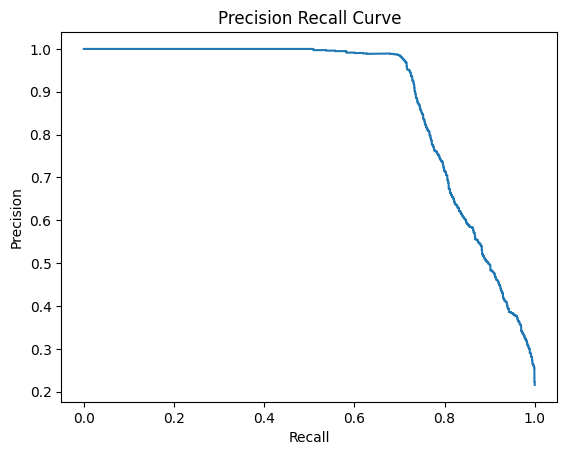

F1 Score: 0.80173775671406
ROC AUC: 0.9349044095633207


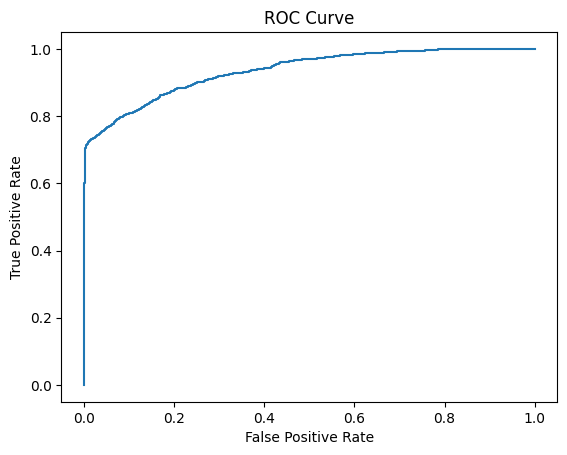

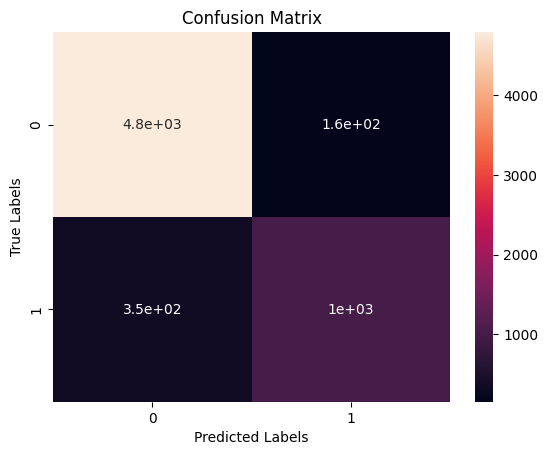

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.97      0.95      4944
           1       0.87      0.75      0.80      1362

    accuracy                           0.92      6306
   macro avg       0.90      0.86      0.88      6306
weighted avg       0.92      0.92      0.92      6306



In [53]:
print("Fitting Random Forest...")
rf_random_search.fit(X_train, y_train)
print("Random Forest search complete.")

print("Evaluating Best Random Forest Model:")
evaluate_model("Tuned Random Forest", rf_random_search.best_estimator_, X_test, y_test)

Fitting AdaBoost...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
AdaBoost search complete.
Evaluating Best AdaBoost Model:
Tuned AdaBoost Metrics:
Accuracy: 0.8880431335236283
Precision: 0.7965641952983725
Recall: 0.6468428781204112


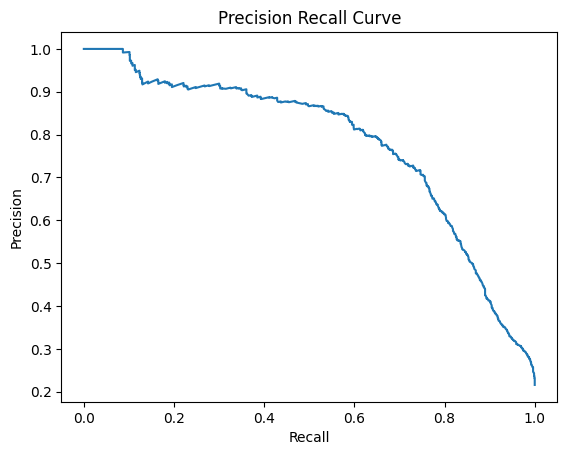

F1 Score: 0.7139384116693679
ROC AUC: 0.9011117615680349


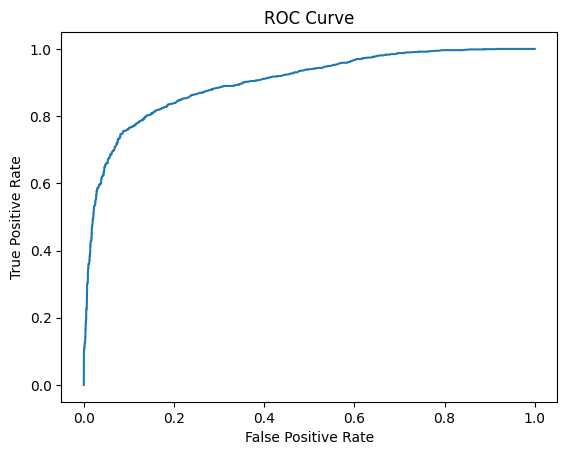

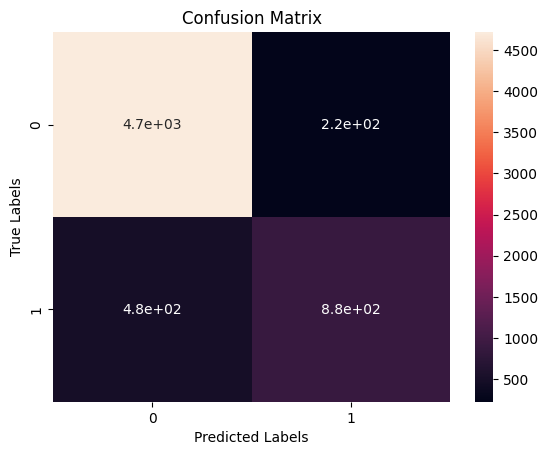

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.95      0.93      4944
           1       0.80      0.65      0.71      1362

    accuracy                           0.89      6306
   macro avg       0.85      0.80      0.82      6306
weighted avg       0.88      0.89      0.88      6306



In [54]:
print("Fitting AdaBoost...")
ada_random_search.fit(X_train, y_train)
print("AdaBoost search complete.")

print("Evaluating Best AdaBoost Model:")
evaluate_model("Tuned AdaBoost", ada_random_search.best_estimator_, X_test, y_test)

In [56]:
print("hyper paramtered xg model outcome:")
print("Best Params:", random_search.best_params_)
print("Best Score (ROC AUC):", random_search.best_score_)
print("Best Estimator:", random_search.best_estimator_)
print()

print("hyper paramtered randomforest model outcome:")
print("Best Params:", rf_random_search.best_params_)
print("Best Score (ROC AUC):", rf_random_search.best_score_)
print("Best Estimator:", rf_random_search.best_estimator_)
print()

print("hyper paramtered adaboost model outcome:")
print("Best Params:", ada_random_search.best_params_)
print("Best Score (ROC AUC):", ada_random_search.best_score_)
print("Best Estimator:", ada_random_search.best_estimator_)

hyper paramtered xg model outcome:
Best Params: {'classifier__colsample_bytree': np.float64(0.5510722820635305), 'classifier__gamma': np.float64(4.2515587449124475), 'classifier__learning_rate': np.float64(0.11189141480541252), 'classifier__max_depth': 6, 'classifier__min_child_weight': 6, 'classifier__n_estimators': 340, 'classifier__subsample': np.float64(0.5684569549189997)}
Best Score (ROC AUC): 0.9462256372068081
Best Estimator: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                     

Optimal Threshold: 0.7724 with Best F1 Score: 0.8335
Optimized XGBoost Metrics:
Accuracy: 0.9367269267364415
Precision: 0.9652173913043478
Recall: 0.7334801762114538


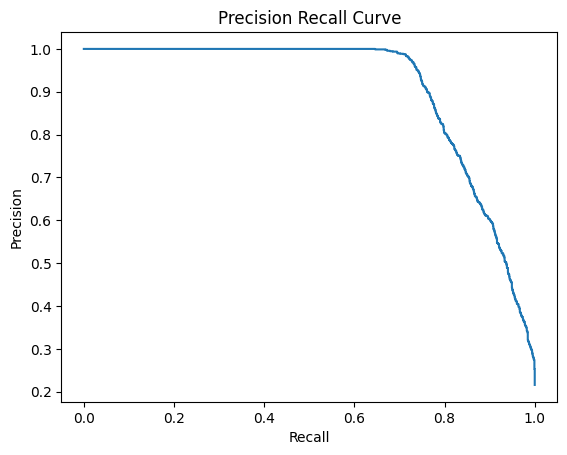

F1 Score: 0.8335419274092616
ROC AUC: 0.951623231588802


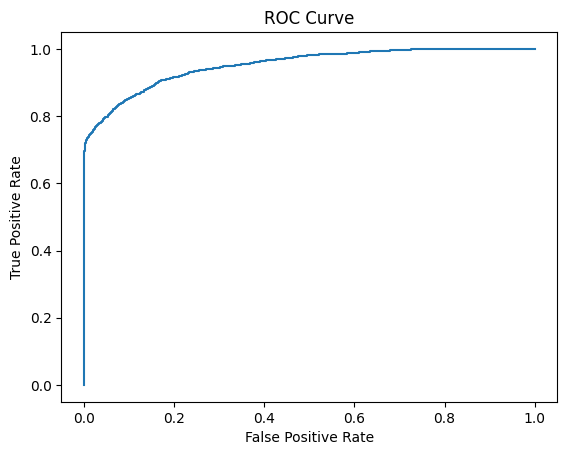

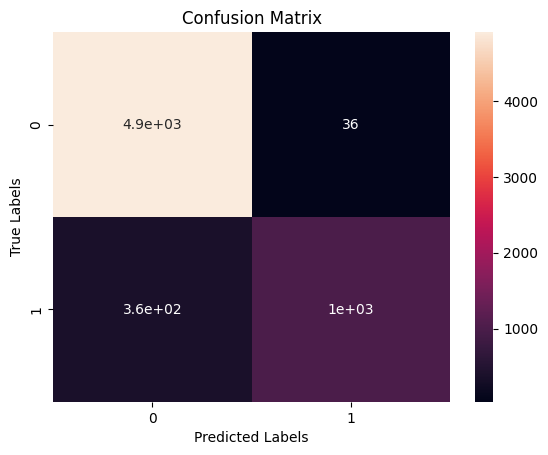

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4944
           1       0.97      0.73      0.83      1362

    accuracy                           0.94      6306
   macro avg       0.95      0.86      0.90      6306
weighted avg       0.94      0.94      0.93      6306



In [62]:
# 1. Get the probability of class 1 from the fitted best XGBoost estimator
# We use the entire X_test to calculate precision, recall, and thresholds accurately
prob = random_search.predict_proba(X_test)

# 2. For each threshold calculate precision and recall
precisions, recalls, thresholds = precision_recall_curve(y_test, prob[:, 1])

# 3. Calculate f1-score for each threshold
# Using small epsilon to prevent division by zero
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# 4. Get the index and value of the threshold that produces the highest F1 score
best_idx = np.argmax(f1)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
print(f"Optimal Threshold: {best_threshold:.4f} with Best F1 Score: {f1[best_idx]:.4f}")

# 5. Evaluate XGBoost model using the optimal threshold
evaluate_model("Optimized XGBoost", random_search, X_test, y_test, threshold=best_threshold)

--- Optimal Threshold for XGBoost Only ---
Best Threshold: 0.7724
Max F1-Score:   0.8335



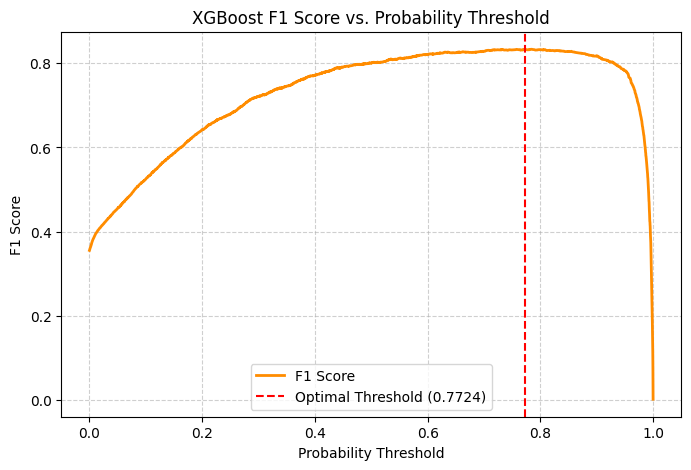

In [90]:
from sklearn.metrics import precision_recall_curve
import numpy as np
import matplotlib.pyplot as plt

# 1. Predict probabilities of the positive class (class 1) for the tuned XGBoost model
y_probs = random_search.best_estimator_.predict_proba(X_test)[:, 1]

# 2. Compute precision, recall, and thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

# 3. Calculate F1 scores for each threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# 4. Find the threshold that yields the maximum F1 score
best_idx = np.argmax(f1_scores)
# Note: thresholds has length len(precisions) - 1
optimal_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
best_f1 = f1_scores[best_idx]

print(f"--- Optimal Threshold for XGBoost Only ---")
print(f"Best Threshold: {optimal_threshold:.4f}")
print(f"Max F1-Score:   {best_f1:.4f}\n")

# 5. Plot F1 Score and Thresholds to visualize the optimum
plt.figure(figsize=(8, 5))
plt.plot(thresholds, f1_scores[:-1], label='F1 Score', color='darkorange', lw=2)
plt.axvline(optimal_threshold, color='red', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.4f})')
plt.xlabel('Probability Threshold')
plt.ylabel('F1 Score')
plt.title('XGBoost F1 Score vs. Probability Threshold')
plt.legend(loc='lower center')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Probability caliberation
####the actual andd predicted probability must be same- linear line then -> good caliberated model
####if it is dofferent then poorly caliberated model
####methods to fix this poorly calierated model -
#### Platt scaling / Sigmoid   -> adjust the probabilities using sigmoid curve
####Tsotonic regression
####Temperature scaling- adjusting confidence of neural network predictions using one temp


In [64]:
#the actual andd predicted probability must be same- linear line then -> good caliberated model
#if it is dofferent then poorly caliberated model
#methods to fix this poorly calierated model -
# Platt scaling / Sigmoid   -> adjust the probabilities using sigmoid curve
#Tsotonic regression
#Temperature scaling- adjusting confidence of neural network predictions using one temp

#steps ---- >   caliberate xg model -> get probabilies -> create calibertaion curve -> plot



from sklearn.calibration import CalibratedClassifierCV, calibration_curve
caliberated_model = CalibratedClassifierCV(random_search.best_estimator_, cv=cv, method='sigmoid')
caliberated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer())]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pi...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.11189141480541252),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=6,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=340,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [66]:
#2
uncaliberated = random_search.best_estimator_.predict_proba(X_test)[:, 1]
caliberated = caliberated_model.predict_proba(X_test)[:, 1]
caliberated

array([0.02284528, 0.01547187, 0.01568114, ..., 0.9455426 , 0.35019305,
       0.07845041], shape=(6306,))

In [67]:
uncaliberated

array([0.08714631, 0.02092612, 0.00926361, ..., 0.99210465, 0.34976012,
       0.37233755], shape=(6306,), dtype=float32)

In [69]:
#3. caliberation curve
actual_uncal,predicted_uncal = calibration_curve(y_test, uncaliberated,n_bins=10)
actual_cal,predicted_cal = calibration_curve(y_test, caliberated,n_bins=10)

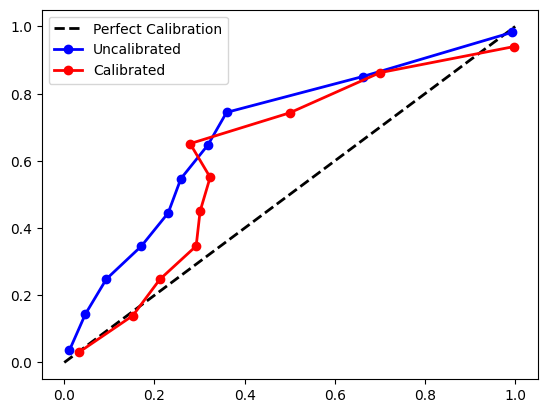

In [77]:
#plot

plt.plot(
    [0,1],[0,1],linestyle='--',linewidth=2,color='black',label='Perfect Calibration'
)
plt.plot(
    actual_uncal, predicted_uncal, linestyle='solid',marker="o", linewidth=2, color='blue',
    label='Uncalibrated'
)

plt.plot(
    actual_cal, predicted_cal, linestyle='solid',marker="o", linewidth=2, color='red',
    label='Calibrated'
)
plt.legend()
#so red line is closer to perfect so we will use that

#SHAP INNTERPRETATION - LOCAL AND GLOBAL
telling which features contributes how much in getting the output
##SHAP helps in understanding why the model makes this decison

In [78]:
!pip install shap

In [86]:
import shap
#2
preprocessor = random_search.best_estimator_.named_steps['preprocessor']
classifier = random_search.best_estimator_.named_steps['classifier']
X_test_transformed = preprocessor.transform(X_test)

# 3. Get the exact feature names generated after One-Hot Encoding
encoded_feature_names = preprocessor.get_feature_names_out()

#4
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=encoded_feature_names)

# 5. Create the SHAP explainer (using TreeExplainer for XGBoost/Random Forest)
explainer = shap.TreeExplainer(classifier)

# 6. Calculate SHAP values for all rows in test set
shap_values = explainer(X_test_transformed)
shap_values

.values =
array([[-0.05871876, -0.91816604,  0.18068182, ..., -0.00886695,
        -0.0013743 , -0.05497322],
       [-0.04072516, -0.4185275 ,  0.03344038, ..., -0.01116697,
        -0.0219654 , -0.06325913],
       [-0.7265055 , -0.7442394 , -0.21256787, ..., -0.00924466,
        -0.01766073, -0.04890407],
       ...,
       [-0.05154135,  1.3257179 ,  1.1737835 , ..., -0.00903   ,
         0.04792439,  0.07994915],
       [ 0.08743052,  0.27158147, -0.02624292, ..., -0.00953501,
        -0.01733616, -0.04594388],
       [ 0.35606924,  1.2747263 , -0.23873721, ..., -0.00903946,
         0.01574777, -0.0342788 ]], shape=(6306, 26), dtype=float32)

.base_values =
array([0.21086441, 0.21086441, 0.21086441, ..., 0.21086441, 0.21086441,
       0.21086441], shape=(6306,), dtype=float32)

.data =
array([[2.6000e+01, 6.7260e+04, 9.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [3.4000e+01, 4.5000e+04, 1.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [4

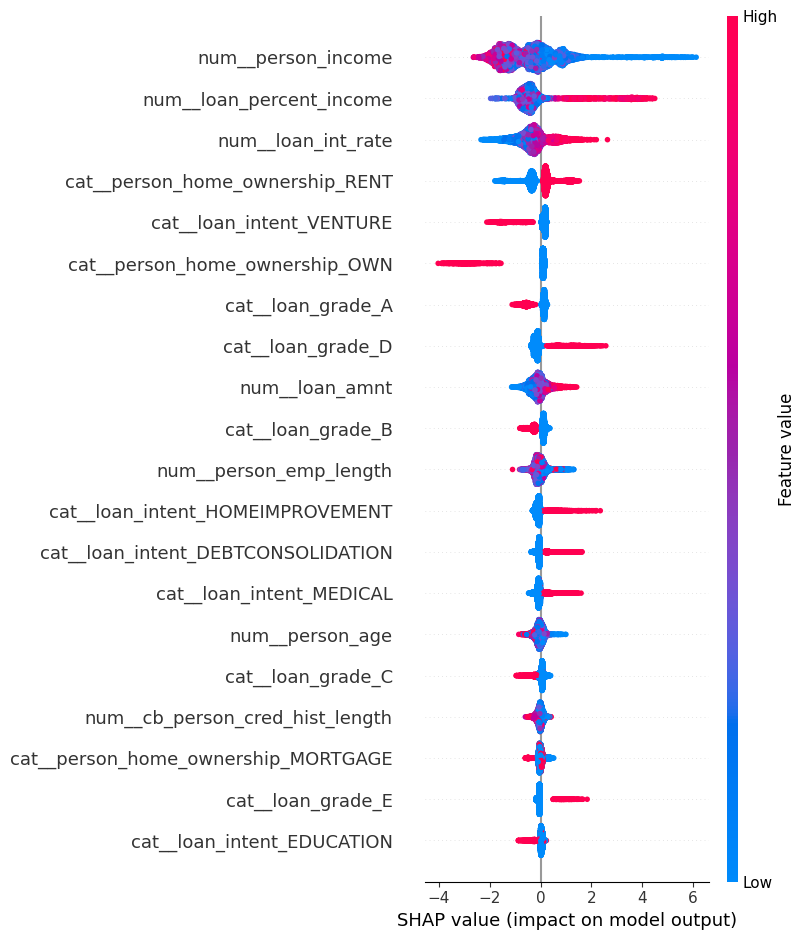

In [87]:
#GLOBAL EXPLAINANTIONS .... ABOVE WAS LOCAL ONE WHERE WE which features contribute to the output row by row.
# Here we are going to do it for overall datasets: which features matter the most for the whole dataset output?
shap.summary_plot(shap_values, X_test_transformed_df)

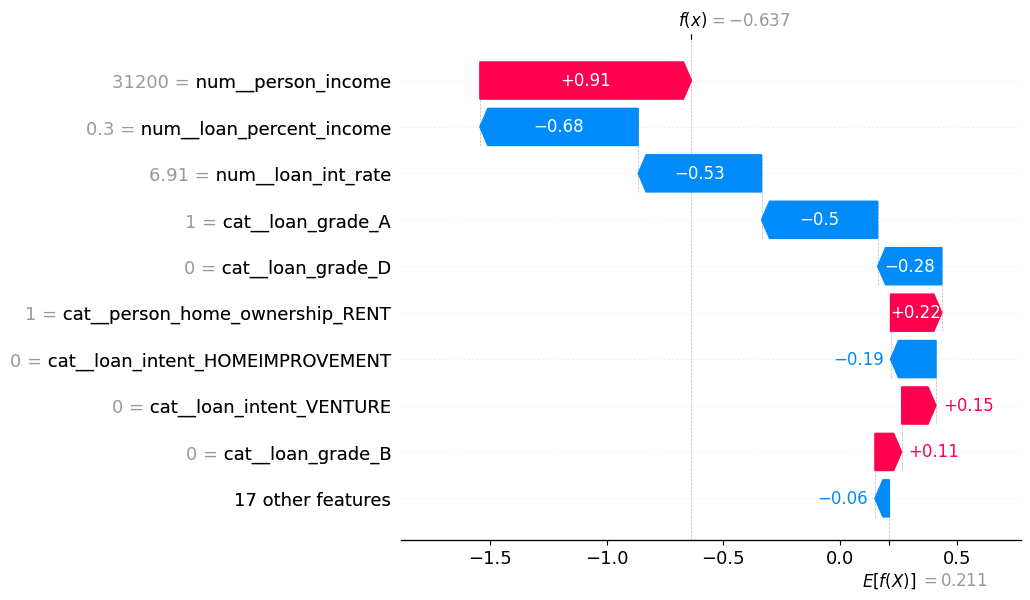

In [99]:
#LOCAL EXPLAINATIONS - choose row of idx 5
row_index=5

#drawing waterfall plot how each feature contributes up or down to outputs...
#Passing only the Explanation slice, which encapsulates base_values and data automatically.
shap.plots.waterfall(shap.Explanation(shap_values[row_index],feature_names=X_test_transformed_df.columns,base_values=explainer.expected_value,data=X_test_transformed[row_index]))
#

#analysing false positive and false positive


In [102]:
y_pred = random_search.best_estimator_.predict(X_test)

# Construct the evaluation DataFrame using only the test dataset rows to match lengths
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

# Display the top few samples comparing actual and predicted outputs
result_df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
10401,26,67260,MORTGAGE,9.0,HOMEIMPROVEMENT,A,6500,7.14,0.10,N,2,0,0
21089,34,45000,MORTGAGE,1.0,VENTURE,B,12000,11.86,0.27,N,9,0,0
31310,43,86044,MORTGAGE,16.0,HOMEIMPROVEMENT,A,6500,7.74,0.08,N,13,0,0
9764,25,25000,RENT,5.0,MEDICAL,B,9000,11.49,0.36,N,2,1,1
1603,21,40000,RENT,5.0,EDUCATION,B,1500,12.18,0.04,N,4,0,0


In [103]:
#false positive- actual was 0 but predicted 1
false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]
#false negative - actual was 1 but predicted 0
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]

In [105]:
false_positive=len(false_positive)
false_negative=len(false_negative)
print(f"Number of False Positives: {false_positive}")
print(f"Number of False Negatives: {false_negative}")

Number of False Positives: 283
Number of False Negatives: 263


NOW STORE THE MODEL

In [106]:
import joblib

# Save the best estimators
joblib.dump(random_search.best_estimator_, 'xgboost_tuned_model.joblib')
joblib.dump(caliberated_model,"credit_risk_model.joblib")
joblib.dump(rf_random_search.best_estimator_, 'random_forest_tuned_model.joblib')
joblib.dump(ada_random_search.best_estimator_, 'adaboost_tuned_model.joblib')

print("Tuned models successfully saved to disk!")

Tuned models successfully saved to disk!
